# Evaluation of the three-way match copilot

Reads the files written by `dotnet run --project tools/DocGen -- eval` and turns them into the tables and charts used in the README.

How the numbers are made: every document in the dataset goes through extraction (Document Intelligence, cached by file hash), matching and the discrepancy rules, in id order, with the same code as the pipeline. Documents of the other split are read as their printed text so the shared state (what earlier invoices already billed) stays complete.

Scoring rule: a document with low confidence that goes to review is **correct**. The only failure that matters is a **wrong automatic approval**: a document with a real injected problem (warning or worse) that was approved without a person.

All data is synthetic. The results show the method on five layouts and one fictional company, not performance in a real plant.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

OUT = Path("out")
DEV = OUT / "dev"      # eval --split dev --tag dev
TEST = OUT / "test"    # eval --split test --tag test  (run once, at the end)
IMG = Path("../docs/img")
IMG.mkdir(parents=True, exist_ok=True)

def load(folder, name):
    path = folder / name
    return pd.read_csv(path) if path.exists() else None

dev, dev_lines, dev_sweep = (load(DEV, n) for n in ("results.csv", "lines.csv", "sweep.csv"))
test, test_lines = (load(TEST, n) for n in ("results.csv", "lines.csv"))
print("dev rows:", None if dev is None else len(dev), "| test rows:", None if test is None else len(test))

dev rows: 179 | test rows: 79


## 1. Headline numbers

In [2]:
def headline(df, label):
    if df is None:
        return None
    real = df[df.real_problem == 1]
    should_pass = df[df.expected_decision == "AutoApproved"]
    return {
        "split": label,
        "documents": len(df),
        "straight-through": f"{(df.decision == 'AutoApproved').sum()} of {len(df)} ({(df.decision == 'AutoApproved').mean():.1%})",
        "wrong auto-approvals": f"{int(df.wrong_auto_approval.sum())} of {len(real)}",
        "false alarms": f"{int(df.false_alarm.sum())} of {len(should_pass)} ({df.false_alarm.sum() / max(len(should_pass), 1):.1%})",
        "correct decision": f"{df.correct_decision.mean():.1%}",
        "could not be read": int((df.decision == "Failed").sum()),
    }

pd.DataFrame([r for r in (headline(dev, "dev"), headline(test, "test")) if r]).set_index("split")

,documents,straight-through,wrong auto-approvals,false alarms,correct decision,could not be read
split,,,,,,
dev,179,120 of 179 (67.0%),0 of 39,20 of 140 (14.3%),88.3%,0
test,79,44 of 79 (55.7%),0 of 22,13 of 57 (22.8%),82.3%,0


## 2. Decisions: expected against actual

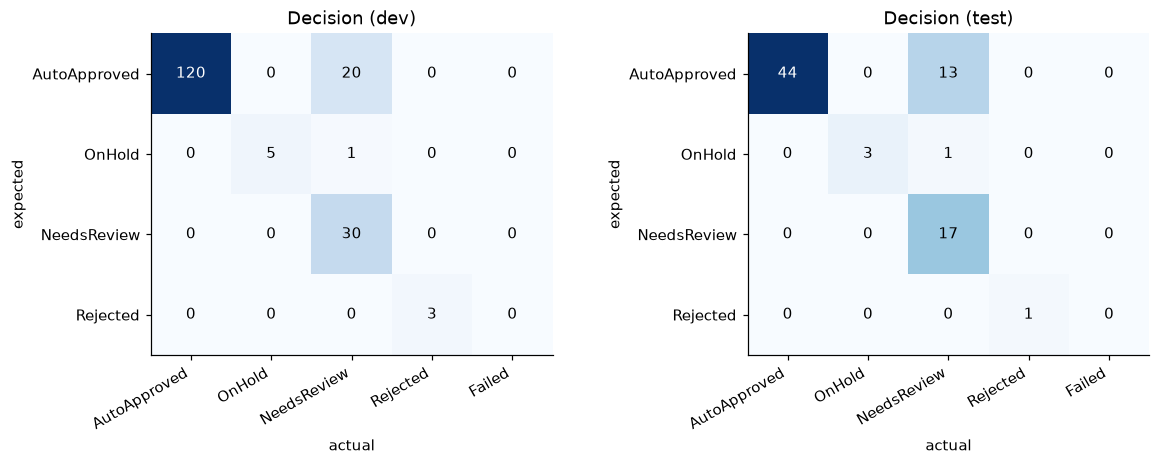

In [3]:
order = ["AutoApproved", "OnHold", "NeedsReview", "Rejected", "Failed"]

def confusion(df, title, ax):
    table = pd.crosstab(df.expected_decision, df.decision).reindex(index=order[:4], columns=order, fill_value=0)
    ax.imshow(table.values, cmap="Blues")
    ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
    ax.set_yticks(range(4), order[:4])
    for (i, j), v in pd.DataFrame(table.values).stack().items():
        ax.text(j, i, int(v), ha="center", va="center", color="white" if v > table.values.max() / 2 else "black")
    ax.set_xlabel("actual"); ax.set_ylabel("expected"); ax.set_title(title)
    return table

frames = [(df, name) for df, name in ((dev, "dev"), (test, "test")) if df is not None]
fig, axes = plt.subplots(1, len(frames), figsize=(5.5 * len(frames), 4.2), squeeze=False)
for ax, (df, name) in zip(axes[0], frames):
    confusion(df, f"Decision ({name})", ax)
fig.tight_layout(); fig.savefig(IMG / "decision_confusion.png"); plt.show()

## 3. Field accuracy by image quality

In [4]:
FIELDS = {"invoice": ["f_number", "f_po_reference", "f_supplier_vat", "f_date", "f_net", "f_vat", "f_gross", "f_iban", "f_line_count"],
          "delivery_note": ["f_number", "f_po_reference", "f_supplier_vat", "f_date", "f_line_count", "f_quantities"]}
QUALITY = ["clean", "scan_light", "scan_heavy", "photo", "photo_real"]

def field_accuracy(df, kind):
    part = df[(df.kind == kind) & (df.decision != "Failed")]
    table = part.groupby("quality")[FIELDS[kind]].mean().reindex([q for q in QUALITY if q in part.quality.unique()])
    table["documents"] = part.groupby("quality").size()
    return table

if dev is not None:
    display(field_accuracy(dev, "invoice").style.format({c: "{:.0%}" for c in FIELDS["invoice"]}).set_caption("Invoices (dev): share of documents with the field correct"))

,f_number,f_po_reference,f_supplier_vat,f_date,f_net,f_vat,f_gross,f_iban,f_line_count,documents
quality,,,,,,,,,,
clean,100%,100%,100%,100%,100%,100%,100%,100%,100%,66
scan_light,100%,100%,100%,100%,100%,100%,100%,100%,100%,11
scan_heavy,100%,100%,100%,100%,75%,100%,100%,100%,100%,4
photo,85%,100%,100%,100%,100%,92%,100%,100%,100%,13


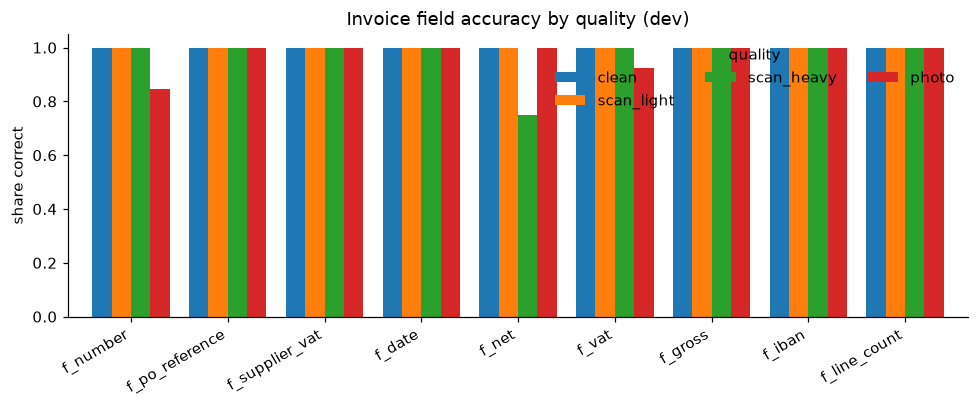

In [5]:
if dev is not None:
    table = field_accuracy(dev, "invoice")[FIELDS["invoice"]]
    ax = table.T.plot.bar(figsize=(9, 3.8), ylim=(0, 1.05), width=0.8)
    ax.set_ylabel("share correct"); ax.set_title("Invoice field accuracy by quality (dev)"); ax.legend(title="quality", ncol=3, frameon=False)
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig(IMG / "field_accuracy.png"); plt.show()

## 4. Line matching: invoice lines matched to the correct order line

In [6]:
if dev_lines is not None and dev is not None:
    joined = dev_lines.merge(dev[["document_id", "quality", "layout"]], on="document_id")
    by_quality = joined.groupby("quality")[["code_ok", "quantity_ok", "unit_price_ok", "matched_po_line_ok"]].mean()
    by_quality["lines"] = joined.groupby("quality").size()
    display(by_quality.reindex([q for q in QUALITY if q in by_quality.index]).style.format({c: "{:.0%}" for c in by_quality.columns[:-1]}))
    print(f"All dev lines: {int(joined.matched_po_line_ok.sum())} of {len(joined)} matched to the correct order line")

,code_ok,quantity_ok,unit_price_ok,matched_po_line_ok,lines
quality,,,,,
clean,100%,98%,100%,100%,175
scan_light,100%,100%,100%,97%,29
scan_heavy,100%,100%,100%,100%,12
photo,100%,93%,100%,100%,41


All dev lines: 256 of 257 matched to the correct order line


## 5. Recall per discrepancy code, and false alarms

In [7]:
def recall(df):
    rows = []
    for _, r in df.dropna(subset=["injected_codes"]).iterrows():
        found = set(str(r.found_codes).split(";")) if isinstance(r.found_codes, str) else set()
        for code in str(r.injected_codes).split(";"):
            rows.append({"code": code, "caught": code in found})
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    g = out.groupby("code").caught.agg(["sum", "count"])
    g["recall"] = g["sum"] / g["count"]
    return g.rename(columns={"sum": "caught", "count": "injected"})

for df, name in frames:
    display(recall(df).style.format({"recall": "{:.0%}"}).set_caption(f"Recall per injected code ({name}). A document that could not be read counts as not caught."))

,caught,injected,recall
code,,,
BANK_ACCOUNT_CHANGED,3,3,100%
DELIVERY_NOTE_MISMATCH,9,10,90%
DUPLICATE_INVOICE,3,3,100%
ITEM_NOT_ON_PO,3,3,100%
NO_PO_REFERENCE,2,2,100%
PARTIAL_DELIVERY,6,6,100%
POSSIBLE_DUPLICATE,3,3,100%
PRICE_ABOVE_PO,3,3,100%
PRICE_BELOW_PO,2,2,100%


,caught,injected,recall
code,,,
BANK_ACCOUNT_CHANGED,3,3,100%
DELIVERY_NOTE_MISMATCH,5,5,100%
DUPLICATE_INVOICE,1,1,100%
ITEM_NOT_ON_PO,1,1,100%
NO_PO_REFERENCE,2,2,100%
PARTIAL_DELIVERY,4,4,100%
POSSIBLE_DUPLICATE,1,1,100%
PRICE_ABOVE_PO,1,1,100%
PRICE_BELOW_PO,1,1,100%


In [8]:
for df, name in frames:
    false_alarms = df[df.false_alarm == 1]
    print(f"{name}: {len(false_alarms)} clean documents sent to review or failed")
    display(false_alarms.groupby("quality").size().rename("false alarms").to_frame().T)
    display(false_alarms.assign(reason=lambda d: d.low_fields.fillna("") + " " + d.found_codes.fillna("")).reason.str.split(r"[; ]").explode().replace("", pd.NA).dropna().value_counts().head(8).rename("most common reason").to_frame())

dev: 20 clean documents sent to review or failed


quality,clean,photo,scan_heavy
false alarms,2,8,10


,most common reason
reason,
LOW_CONFIDENCE,15
UOM_MISMATCH,11
Line1.Quantity,6
Line2.Quantity,6
Line3.Quantity,5
PurchaseOrderReference,5
DELIVERY_NOTE_MISMATCH,2
DeliveryNoteNumber,2


test: 13 clean documents sent to review or failed


quality,clean,photo,photo_real,scan_heavy,scan_light
false alarms,3,4,1,4,1


,most common reason
reason,
LOW_CONFIDENCE,9
UOM_MISMATCH,8
Line1.Quantity,5
PurchaseOrderReference,5
DeliveryNoteNumber,3
SupplierVatNumber,3
Line3.Quantity,2
DELIVERY_NOTE_MISMATCH,1


## 6. Confidence threshold

Tuned on **dev only**, then applied once to test. The curve shows what each threshold costs: a higher threshold sends more good documents to review (lower straight-through rate); a lower one risks wrong approvals. The wrong-approval count should stay at zero across the useful range.

threshold,straight_through_rate,auto_approved,wrong_auto_approvals,false_alarms
0.600000,67.0%,120,0,20
0.700000,67.0%,120,0,20
0.800000,67.0%,120,0,20
0.900000,65.4%,117,0,23


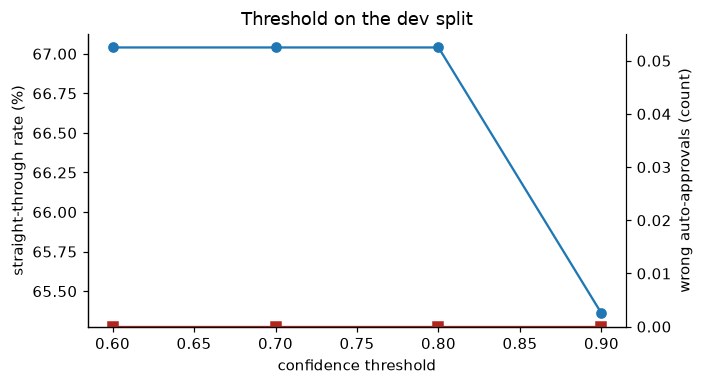

In [9]:
if dev_sweep is not None:
    display(dev_sweep[["threshold", "straight_through_rate", "auto_approved", "wrong_auto_approvals", "false_alarms"]].style.format({"straight_through_rate": "{:.1%}"}).hide(axis="index"))
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(dev_sweep.threshold, dev_sweep.straight_through_rate * 100, marker="o", label="straight-through rate (%)")
    ax.set_xlabel("confidence threshold"); ax.set_ylabel("straight-through rate (%)")
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
    ax2.plot(dev_sweep.threshold, dev_sweep.wrong_auto_approvals, marker="s", color="#b3261e", label="wrong auto-approvals")
    ax2.set_ylabel("wrong auto-approvals (count)"); ax2.set_ylim(bottom=0)
    ax.set_title("Threshold on the dev split")
    fig.tight_layout(); fig.savefig(IMG / "threshold_sweep.png"); plt.show()

## 7. Delivery-note models: layout and rules, neural, template

In [10]:
DN_RUNS = {"layout + rules": ["dn-layout-v2", "dn-layout-test"], "neural": ["dn-neural-v2", "dn-neural-test"], "template": ["dn-template-v2", "dn-template-test"]}
DN_FIELDS = ["f_number", "f_po_reference", "f_supplier_vat", "f_date", "f_line_count", "f_quantities"]
rows = []
for name, folders in DN_RUNS.items():
    frames_ = [f for f in (load(OUT / folder, "results.csv") for folder in folders) if f is not None]
    if not frames_:
        continue
    df = pd.concat(frames_)
    notes = df[(df.kind == "delivery_note") & (df.decision != "Failed")]
    for group, part in (("dev", notes[notes.split == "dev"]), ("test, known layouts", notes[(notes.split == "test") & (notes.held_out == 0)]), ("held-out layout", notes[notes.held_out == 1])):
        if len(part):
            rows.append({"model": name, "documents": group, "n": len(part), **{f: part[f].mean() for f in DN_FIELDS}})
dn = pd.DataFrame(rows)
if len(dn):
    display(dn.style.format({f: "{:.0%}" for f in DN_FIELDS}).hide(axis="index"))
else:
    print("No delivery-note runs found in out/dn-*. Run eval with --dn-model and --tag dn-layout, dn-neural, dn-template (and the -test tags).")

model,documents,n,f_number,f_po_reference,f_supplier_vat,f_date,f_line_count,f_quantities
layout + rules,dev,85,96%,100%,100%,94%,95%,94%
layout + rules,"test, known layouts",24,100%,100%,100%,100%,100%,100%
layout + rules,held-out layout,13,92%,100%,100%,92%,100%,100%
neural,dev,85,99%,100%,100%,100%,99%,93%
neural,"test, known layouts",24,100%,100%,100%,100%,100%,92%
neural,held-out layout,13,100%,100%,100%,100%,85%,77%
template,dev,85,99%,96%,98%,89%,98%,96%
template,"test, known layouts",24,100%,100%,100%,88%,100%,100%
template,held-out layout,13,100%,100%,100%,0%,77%,69%


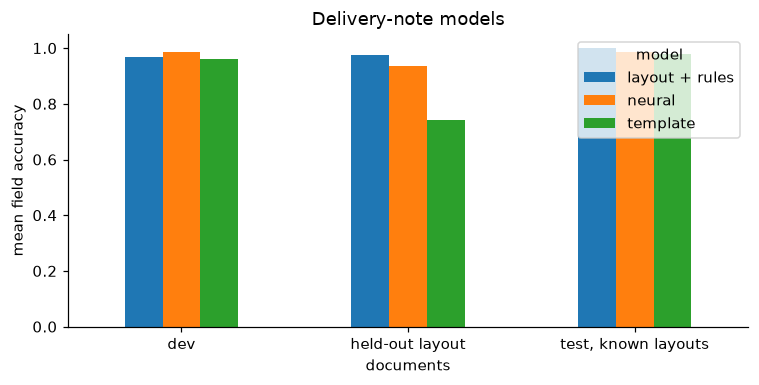

In [11]:
if len(dn):
    pivot = dn.assign(score=dn[DN_FIELDS].mean(axis=1)).pivot(index="documents", columns="model", values="score")
    ax = pivot.plot.bar(figsize=(7, 3.6), ylim=(0, 1.05))
    ax.set_ylabel("mean field accuracy"); ax.set_title("Delivery-note models"); plt.xticks(rotation=0); plt.tight_layout()
    plt.savefig(IMG / "delivery_note_models.png"); plt.show()

## 8. Cost per document

List prices change. Check the Azure pricing pages and edit the constants before quoting a number. Document Intelligence is billed per page (all documents here are one page); the explanation is billed per token and runs only for documents that need a decision. Token counts come from `DocGen explain` (its last line) or from the `PromptTokens` and `CompletionTokens` columns of `ap.MatchExplanation`.

In [12]:
# Edit these before quoting a number.
USD_PER_1000_PAGES = {"prebuilt-invoice": 10.0, "prebuilt-layout": 10.0, "custom": 30.0}
USD_PER_MILLION_TOKENS = {"input": 0.40, "output": 1.60}   # gpt-4.1-mini list price
AVG_PROMPT_TOKENS, AVG_COMPLETION_TOKENS = 1061, 226          # DocGen explain v2: 16978 / 3620 tokens over 16 documents, retries included

if dev is not None:
    read = dev[dev.decision != "Failed"]
    pages = read.assign(pages=read.pages.fillna(1))
    di = pages.apply(lambda r: r.pages * USD_PER_1000_PAGES["custom" if str(r.extract_model).startswith("delivery-note") else r.extract_model if r.extract_model in USD_PER_1000_PAGES else "prebuilt-layout"] / 1000, axis=1)
    needs_decision = read.decision.isin(["NeedsReview", "OnHold"])
    llm = (AVG_PROMPT_TOKENS * USD_PER_MILLION_TOKENS["input"] + AVG_COMPLETION_TOKENS * USD_PER_MILLION_TOKENS["output"]) / 1e6
    total = di.sum() + needs_decision.sum() * llm
    print(f"Reading: {di.sum() / len(read) * 100:.2f} US cents per document on average")
    print(f"Explanation, only if the document needs a decision ({needs_decision.mean():.0%} of documents): {llm * 100:.2f} US cents each")
    print(f"All in: {total / len(read) * 100:.2f} US cents per document (list price, dev split)")

Reading: 1.95 US cents per document on average
Explanation, only if the document needs a decision (31% of documents): 0.08 US cents each
All in: 1.97 US cents per document (list price, dev split)


## 9. Processing time

Time per document comes from the real pipeline (upload to final status), not from this run, because the eval runs from the cache. Upload about ten documents, then run this in Application Insights (Logs):

```kusto
traces
| where message startswith "Processed in"
| extend ms = toint(extract(@"Processed in (\d+) ms", 1, message))
| summarize median_ms = percentile(ms, 50), p95_ms = percentile(ms, 95), documents = count()
```

If you export the result as `out/timings.csv` with a column `ms`, the cell below summarises it.

In [13]:
timings = load(OUT, "timings.csv")
if timings is not None:
    print(f"median {timings.ms.median() / 1000:.1f} s, p95 {timings.ms.quantile(0.95) / 1000:.1f} s over {len(timings)} documents")
else:
    print("No out/timings.csv yet.")

median 9.7 s, p95 11.6 s over 8 documents


## Limitations

- Synthetic data: five layouts, one fictional company, injected errors written by the same person who wrote the rules. Recall is partly circular; the held-out layout and the scans are the honest part.
- Dev is small. Percentages move by several points when a single document changes, so counts are shown next to them.
- The threshold was chosen on dev. The test numbers come from one run.
- Photos are simulated except five real ones.